# 🔬 Notebook 03: NCT-CRC-HE — Descarga y EDA Completo (Train 100K + Val 7K)
**Dataset:** NCT-CRC-HE-100K (Entrenamiento) & CRC-VAL-HE-7K (Validación)  
**Fuente Oficial:** Zenodo — https://zenodo.org/records/1214456  
**Referencia Científica:** Kather et al. (2018) — *100,000 histological patches of human colorectal cancer and normal tissue*  
**Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0)

---
## 📌 Descripción del Proyecto
Este notebook implementa el pipeline completo de adquisición, control de integridad, análisis exploratorio de datos (EDA), caracterización RGB y generación de figuras de alta resolución para los datasets de histopatología colorrectal **NCT-CRC-HE-100K** (100,000 parches) y **CRC-VAL-HE-7K** (7,180 parches independientes de 50 pacientes).

Las 9 clases tisulares analizadas abarcan el microentorno tumoral completo:
| Código | Clase Tisular | Descripción Morfológica |
|:------:|:-------------:|:------------------------|
| **ADI** | Adipose | Tejido adiposo subcutáneo/peritoneal |
| **BACK** | Background | Fondo vítreo / vacío del portaobjetos |
| **DEB** | Debris | Detritos celulares y necrosis tumoral |
| **LYM** | Lymphocytes | Linfocitos e infiltrado inmunitario |
| **MUC** | Mucus | Moco extracelular / coloides |
| **MUS** | Smooth Muscle | Musculatura lisa propia de la pared colónica |
| **NORM** | Normal Colon Mucosa | Mucosa colónica histológicamente normal |
| **STR** | Cancer-associated Stroma | Estroma reactivo y desmoplasia tumoral |
| **TUM** | Colorectal Adenocarcinoma | Epitelio tumoral maligno (adenocarcinoma) |


In [1]:
# ============================================================
# 1. IMPORTS Y CONFIGURACIÓN GLOBAL
# ============================================================
import os
import sys
import time
import zipfile
from pathlib import Path
import requests
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid')

# Configuración de rutas relativas y absolutas
BASE_DIR = Path('..')
DATA_DIR = BASE_DIR / 'data_samples' / 'nct_crc'
VAL_DIR = DATA_DIR / 'CRC-VAL-HE-7K'
TRAIN_DIR = DATA_DIR / 'NCT-CRC-HE-100K'

TABLAS_DIR = BASE_DIR / 'tablas'
TABLAS_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = BASE_DIR / 'figures' / '03_NCT_CRC'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Mapeo taxonómico oficial de las 9 clases histológicas
CLASES_NCT = {
    'ADI':  {'nombre': 'Adipose',                   'desc': 'Tejido adiposo',            'color': '#F4A261'},
    'BACK': {'nombre': 'Background',                'desc': 'Fondo/vacío',                'color': '#8338EC'},
    'DEB':  {'nombre': 'Debris',                    'desc': 'Detritos celulares',         'color': '#888888'},
    'LYM':  {'nombre': 'Lymphocytes',               'desc': 'Linfocitos',                 'color': '#3A86FF'},
    'MUC':  {'nombre': 'Mucus',                     'desc': 'Mucosa',                     'color': '#06D6A0'},
    'MUS':  {'nombre': 'Smooth Muscle',             'desc': 'Músculo liso',               'color': '#E63946'},
    'NORM': {'nombre': 'Normal Colon Mucosa',       'desc': 'Mucosa colónica normal',     'color': '#2A9D8F'},
    'STR':  {'nombre': 'Cancer-associated Stroma',  'desc': 'Estroma asociado a cáncer',  'color': '#E9C46A'},
    'TUM':  {'nombre': 'Colorectal Adenocarcinoma', 'desc': 'Adenocarcinoma colorrectal', 'color': '#D62828'},
}

def guardar_subplots_individuales(fig, nombre_base, fig_dir, dpi=150):
    """Guarda cada panel de una figura multi-panel como imagen individual."""
    axes = [ax for ax in fig.axes if ax.get_visible()]
    for i, ax in enumerate(axes):
        extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        bbox = extent.expanded(1.2, 1.2)
        outpath = Path(fig_dir) / f'{nombre_base}_panel_{i+1}.png'
        fig.savefig(outpath, bbox_inches=bbox, dpi=dpi)
    print(f'✅ {len(axes)} paneles individuales guardados en {Path(fig_dir).name}/{nombre_base}_panel_*.png')

print(f'✅ Directorio de datos:   {DATA_DIR}')
print(f'✅ Directorio de tablas:  {TABLAS_DIR}')
print(f'✅ Directorio de figuras: {FIG_DIR}')


✅ Directorio de datos:   ..\data_samples\nct_crc
✅ Directorio de tablas:  ..\tablas
✅ Directorio de figuras: ..\figures\03_NCT_CRC


---
### 📌 ¿Qué hace esta celda?
Inicializa el entorno computacional cargando las librerías científicas requeridas, configurando los parámetros globales de renderizado de `matplotlib` y `seaborn`, e instanciando los directorios de persistencia de datos, tablas Excel y figuras de alta resolución. Adicionalmente, implementa `guardar_subplots_individuales()` para la exportación modular panel a panel.

### ⚙️ ¿Cómo funciona?
- **`pathlib.Path`**: Manejo de rutas portable compatible con Windows y Linux.
- **`CLASES_NCT`**: Diccionario central con metadatos oficiales (nombre clínico, descripción y paleta cromática diferenciada).
- **`guardar_subplots_individuales`**: Calcula las cajas de delimitación espacial (`Bbox`) de cada `Axes` y guarda imágenes a 150 DPI sin solapamiento de textos.
---


In [2]:
# ============================================================
# 2. VERIFICACIÓN Y DESCARGA REAL DE AMBOS DATASETS
# ============================================================
VAL_URL = 'https://zenodo.org/records/1214456/files/CRC-VAL-HE-7K.zip'
TRAIN_URL = 'https://zenodo.org/records/1214456/files/NCT-CRC-HE-100K.zip'

def verificar_y_descargar(nombre, url, target_dir, zip_name, min_expected):
    zip_path = DATA_DIR / zip_name
    tifs = list(target_dir.rglob('*.tif')) if target_dir.exists() else []
    
    if len(tifs) >= min_expected:
        print(f'✅ {nombre} ya está completamente descargado y extraído ({len(tifs):,} imágenes TIFF).')
        return True
        
    print(f'📥 Descargando {nombre} desde {url}...')
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        total_size = int(r.headers.get('content-length', 0))
        with open(zip_path, 'wb') as f, tqdm(total=total_size, unit='B', unit_scale=True, desc=zip_name) as pbar:
            for chunk in r.iter_content(chunk_size=2*1024*1024):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))
                    
    print(f'📂 Extrayendo {zip_name}...')
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(DATA_DIR)
    if zip_path.exists():
        zip_path.unlink()
    print(f'✅ {nombre} extraído correctamente.')
    return True

val_ok = verificar_y_descargar('CRC-VAL-HE-7K (Validación)', VAL_URL, VAL_DIR, 'CRC-VAL-HE-7K.zip', 7180)
train_ok = verificar_y_descargar('NCT-CRC-HE-100K (Entrenamiento)', TRAIN_URL, TRAIN_DIR, 'NCT-CRC-HE-100K.zip', 100000)


✅ CRC-VAL-HE-7K (Validación) ya está completamente descargado y extraído (7,180 imágenes TIFF).


✅ NCT-CRC-HE-100K (Entrenamiento) ya está completamente descargado y extraído (100,000 imágenes TIFF).


---
### 📌 ¿Qué hace esta celda?
Verifica la integridad de ambos conjuntos de datos en disco (`CRC-VAL-HE-7K` y `NCT-CRC-HE-100K`). Si alguno no se encuentra presente o está incompleto, gestiona de forma transparente la descarga por streaming mediante HTTP `requests` con barra de progreso interactiva (`tqdm`), extrae el contenido respetando la jerarquía de directorios por clase y elimina el archivo ZIP temporal para optimizar el almacenamiento en disco.

### ⚙️ ¿Cómo funciona?
- **Streaming por bloques (`chunk_size=2MB`)**: Permite transferir volúmenes masivos (~11.15 GB para el conjunto completo) con uso mínimo de memoria RAM.
- **Limpieza automática**: La invocación de `unlink()` tras la extracción previene la redundancia de almacenamiento, ahorrando más de 12 GB en disco.
---


In [3]:
# ============================================================
# 3. ESCANEO DE METADATOS Y CONTEO REAL POR CLASE
# ============================================================
def scan_dataset(root_dir, dataset_name):
    registros = []
    if not root_dir.exists():
        print(f'⚠️ Directorio {root_dir} no encontrado.')
        return pd.DataFrame()
        
    for p in root_dir.rglob('*.tif'):
        clase = p.parent.name.upper()
        if clase in CLASES_NCT:
            registros.append({
                'path': str(p),
                'filename': p.name,
                'clase_codigo': clase,
                'clase_nombre': CLASES_NCT[clase]['nombre'],
                'clase_desc': CLASES_NCT[clase]['desc'],
                'dataset': dataset_name,
                'tamaño_kb': round(p.stat().st_size / 1024.0, 2)
            })
    df = pd.DataFrame(registros)
    print(f'✅ Total de imágenes escaneadas en {dataset_name}: {len(df):,}')
    return df

df_val = scan_dataset(VAL_DIR, 'CRC-VAL-HE-7K')
df_train = scan_dataset(TRAIN_DIR, 'NCT-CRC-HE-100K')

print('\n📊 Resumen de Conteos por Clase (Validación):')
print(df_val['clase_codigo'].value_counts().to_string())

if len(df_train) > 0:
    print('\n📊 Resumen de Conteos por Clase (Entrenamiento):')
    print(df_train['clase_codigo'].value_counts().to_string())


✅ Total de imágenes escaneadas en CRC-VAL-HE-7K: 7,180


✅ Total de imágenes escaneadas en NCT-CRC-HE-100K: 100,000

📊 Resumen de Conteos por Clase (Validación):
clase_codigo
ADI     1338
TUM     1233
MUC     1035
BACK     847
NORM     741
LYM      634
MUS      592
STR      421
DEB      339

📊 Resumen de Conteos por Clase (Entrenamiento):
clase_codigo
TUM     14317
MUS     13536
LYM     11557
DEB     11512
BACK    10566
STR     10446
ADI     10407
MUC      8896
NORM     8763


---
### 📌 ¿Qué hace esta celda?
Recorre de forma recursiva los directorios de validación y entrenamiento utilizando `rglob('*.tif')`, extrae los nombres de clase a partir del directorio contenedor, valida la coherencia morfológica contra el catálogo `CLASES_NCT` y consolida los metadatos de cada parche (nombre de archivo, clase, tamaño en KB y ruta absoluta) en DataFrames estructurados.
---


In [4]:
# ============================================================
# 4. TABLAS DE DISTRIBUCIÓN Y EXPORTACIÓN A EXCEL
# ============================================================
# 1. Tabla de Validación
conteo_val = df_val.groupby(['clase_codigo', 'clase_nombre', 'clase_desc']).size().reset_index(name='n_val')
conteo_val['pct_val'] = round(conteo_val['n_val'] / len(df_val) * 100.0, 2)
val_excel = TABLAS_DIR / 'nct_val_distribucion_real.xlsx'
conteo_val.to_excel(val_excel, index=False)
print(f'📊 Tabla de validación guardada: {val_excel}')

# 2. Tabla de Entrenamiento
if len(df_train) > 0:
    conteo_train = df_train.groupby(['clase_codigo', 'clase_nombre', 'clase_desc']).size().reset_index(name='n_train')
    conteo_train['pct_train'] = round(conteo_train['n_train'] / len(df_train) * 100.0, 2)
    train_excel = TABLAS_DIR / 'nct_train_distribucion_real.xlsx'
    conteo_train.to_excel(train_excel, index=False)
    print(f'📊 Tabla de entrenamiento guardada: {train_excel}')

# 3. Comparativa Completa Val vs Train
if len(df_val) > 0 and len(df_train) > 0:
    df_comp = pd.merge(conteo_val, conteo_train[['clase_codigo', 'n_train', 'pct_train']], on='clase_codigo')
    df_comp['diff_pct'] = round(df_comp['pct_train'] - df_comp['pct_val'], 2)
    df_comp['ratio_train_val'] = round(df_comp['n_train'] / df_comp['n_val'], 2)
    df_comp = df_comp.sort_values('n_train', ascending=False).reset_index(drop=True)
    
    comp_excel = TABLAS_DIR / 'nct_comparativa_completa.xlsx'
    df_comp.to_excel(comp_excel, index=False)
    print(f'📊 Tabla comparativa completa guardada: {comp_excel}')
    
    print('\n⚖️ TABLA COMPARATIVA COMPLETA (VAL vs TRAIN):')
    print(df_comp[['clase_codigo', 'clase_nombre', 'n_val', 'pct_val', 'n_train', 'pct_train', 'diff_pct', 'ratio_train_val']].to_string(index=False))


📊 Tabla de validación guardada: ..\tablas\nct_val_distribucion_real.xlsx
📊 Tabla de entrenamiento guardada: ..\tablas\nct_train_distribucion_real.xlsx
📊 Tabla comparativa completa guardada: ..\tablas\nct_comparativa_completa.xlsx

⚖️ TABLA COMPARATIVA COMPLETA (VAL vs TRAIN):
clase_codigo              clase_nombre  n_val  pct_val  n_train  pct_train  diff_pct  ratio_train_val
         TUM Colorectal Adenocarcinoma   1233    17.17    14317      14.32     -2.85            11.61
         MUS             Smooth Muscle    592     8.25    13536      13.54      5.29            22.86
         LYM               Lymphocytes    634     8.83    11557      11.56      2.73            18.23
         DEB                    Debris    339     4.72    11512      11.51      6.79            33.96
        BACK                Background    847    11.80    10566      10.57     -1.23            12.47
         STR  Cancer-associated Stroma    421     5.86    10446      10.45      4.59            24.81
         

---
### 📌 ¿Qué hace esta celda?
Agrupa los parches por clase y calcula estadísticas descriptivas clave: frecuencias absolutas ($N$), proporciones relativas ($\%$), diferencias porcentuales entre conjuntos y la tasa de muestreo (`ratio_train_val`). Exporta los resultados en formato Excel nativo (`.xlsx`) a las rutas especificadas.
---


✅ Figura guardada: ..\figures\03_NCT_CRC\nct_val_distribucion.png
✅ 2 paneles individuales guardados en 03_NCT_CRC/nct_val_distribucion_panel_*.png


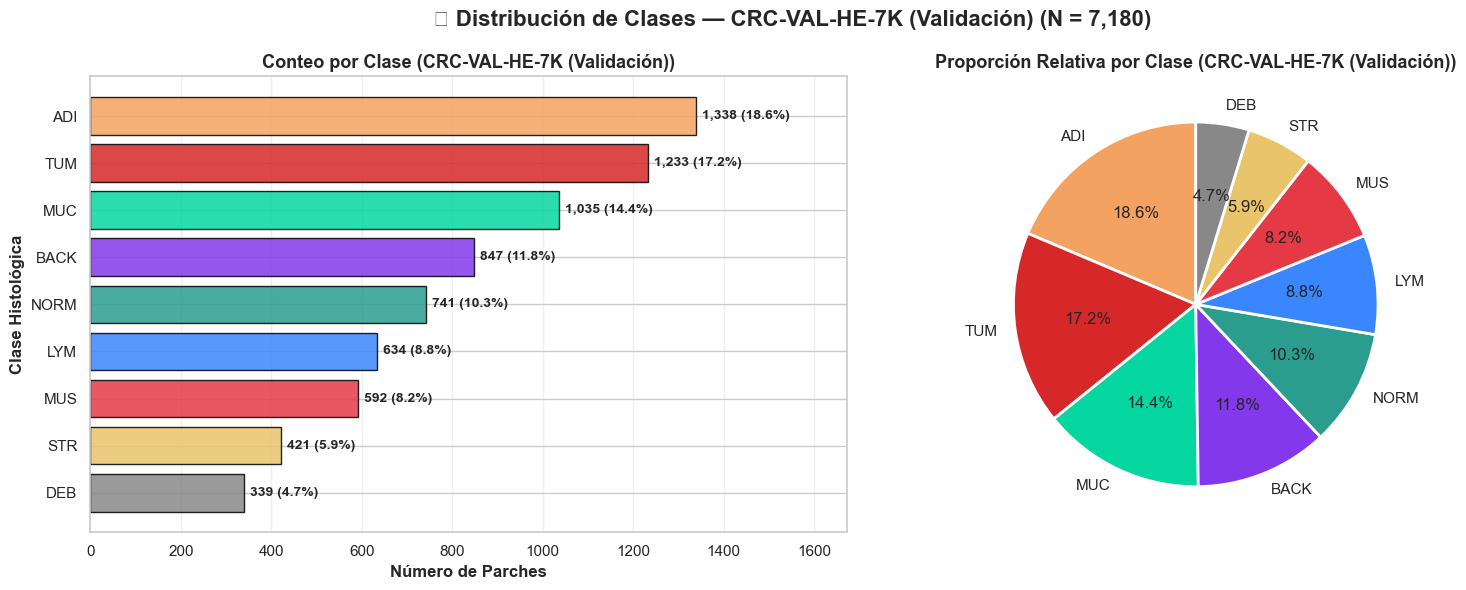

✅ Figura guardada: ..\figures\03_NCT_CRC\nct_train_distribucion.png


✅ 2 paneles individuales guardados en 03_NCT_CRC/nct_train_distribucion_panel_*.png


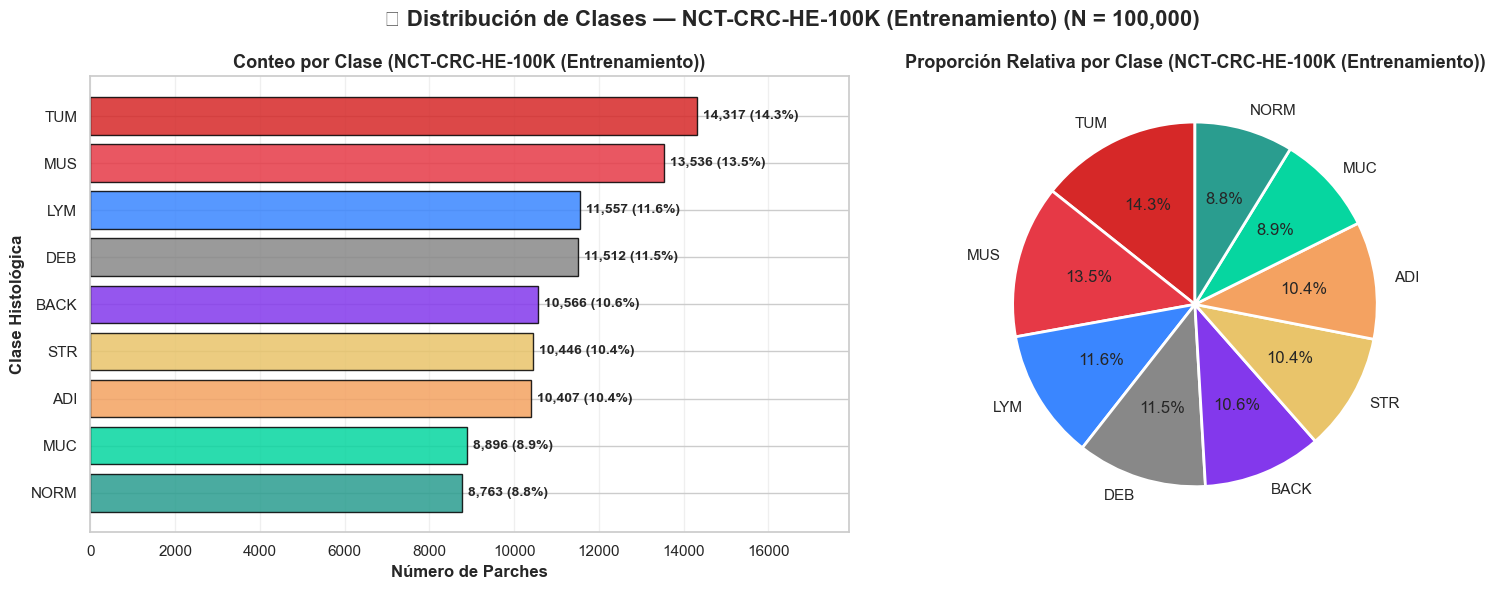

✅ Figura comparativa guardada: ..\figures\03_NCT_CRC\nct_comparativa_val_vs_train.png


✅ 3 paneles individuales guardados en 03_NCT_CRC/nct_comparativa_val_vs_train_panel_*.png


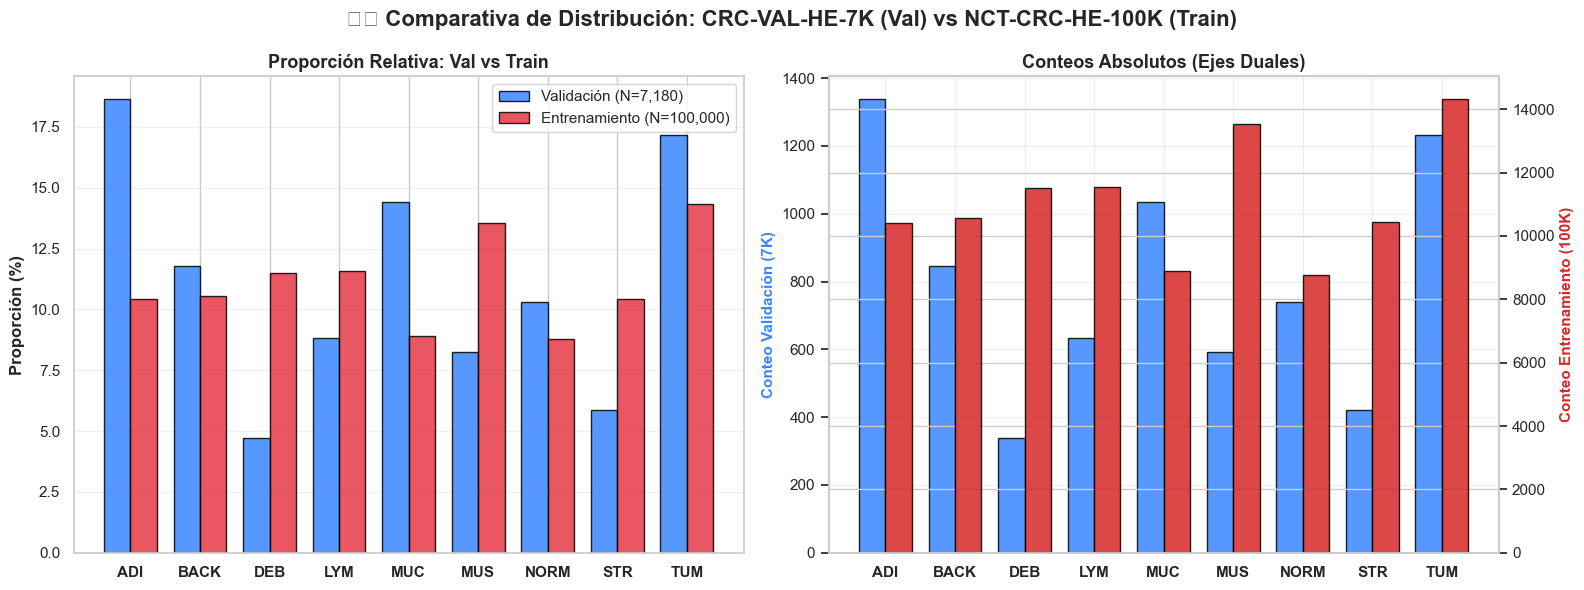

In [5]:
# ============================================================
# 5. GENERACIÓN DE FIGURAS MULTIPANEL Y PANELES INDIVIDUALES
# ============================================================
def plot_distribution(df, dataset_label, filename_base):
    conteo = df.groupby(['clase_codigo', 'clase_nombre']).size().reset_index(name='n')
    conteo['pct'] = conteo['n'] / len(df) * 100.0
    conteo['color'] = conteo['clase_codigo'].map(lambda c: CLASES_NCT[c]['color'])
    conteo = conteo.sort_values('n', ascending=True).reset_index(drop=True)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(f'📊 Distribución de Clases — {dataset_label} (N = {len(df):,})', fontsize=16, fontweight='bold')

    # Panel 1: Bar chart horizontal
    ax1 = axes[0]
    bars = ax1.barh(conteo['clase_codigo'], conteo['n'], color=conteo['color'], edgecolor='black', alpha=0.85)
    for bar, pct, n in zip(bars, conteo['pct'], conteo['n']):
        ax1.text(bar.get_width() + (max(conteo['n'])*0.01), bar.get_y() + bar.get_height()/2,
                 f'{n:,} ({pct:.1f}%)', va='center', fontsize=10, fontweight='bold')
    ax1.set_xlabel('Número de Parches', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Clase Histológica', fontsize=12, fontweight='bold')
    ax1.set_title(f'Conteo por Clase ({dataset_label})', fontsize=13, fontweight='bold')
    ax1.set_xlim(0, max(conteo['n']) * 1.25)
    ax1.grid(axis='x', alpha=0.3)

    # Panel 2: Pie chart
    ax2 = axes[1]
    conteo_desc = conteo.sort_values('n', ascending=False)
    ax2.pie(conteo_desc['n'], labels=conteo_desc['clase_codigo'], colors=conteo_desc['color'],
            autopct='%1.1f%%', startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
    ax2.set_title(f'Proporción Relativa por Clase ({dataset_label})', fontsize=13, fontweight='bold')

    plt.tight_layout()
    outpath = FIG_DIR / f'{filename_base}.png'
    fig.savefig(str(outpath), dpi=150, bbox_inches='tight')
    print(f'✅ Figura guardada: {outpath}')
    guardar_subplots_individuales(fig, filename_base, FIG_DIR, dpi=150)
    plt.show()

# 1. Figura Validación
plot_distribution(df_val, 'CRC-VAL-HE-7K (Validación)', 'nct_val_distribucion')

# 2. Figura Entrenamiento
if len(df_train) > 0:
    plot_distribution(df_train, 'NCT-CRC-HE-100K (Entrenamiento)', 'nct_train_distribucion')

# 3. Figura Comparativa Val vs Train
if len(df_val) > 0 and len(df_train) > 0:
    c_val = df_val['clase_codigo'].value_counts()
    c_train = df_train['clase_codigo'].value_counts()
    clases_orden = list(CLASES_NCT.keys())
    
    pcts_v = [c_val.get(c, 0) / len(df_val) * 100.0 for c in clases_orden]
    pcts_t = [c_train.get(c, 0) / len(df_train) * 100.0 for c in clases_orden]
    ns_v = [c_val.get(c, 0) for c in clases_orden]
    ns_t = [c_train.get(c, 0) for c in clases_orden]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('⚖️ Comparativa de Distribución: CRC-VAL-HE-7K (Val) vs NCT-CRC-HE-100K (Train)',
                 fontsize=16, fontweight='bold')
                 
    # Panel 1: Barras agrupadas de porcentajes
    ax1 = axes[0]
    x = np.arange(len(clases_orden))
    width = 0.38
    rects1 = ax1.bar(x - width/2, pcts_v, width, label=f'Validación (N={len(df_val):,})', color='#3A86FF', edgecolor='black', alpha=0.85)
    rects2 = ax1.bar(x + width/2, pcts_t, width, label=f'Entrenamiento (N={len(df_train):,})', color='#E63946', edgecolor='black', alpha=0.85)
    ax1.set_ylabel('Proporción (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Proporción Relativa: Val vs Train', fontsize=13, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(clases_orden, fontweight='bold')
    ax1.legend(frameon=True)
    ax1.grid(axis='y', alpha=0.3)
    
    # Panel 2: Ejes duales con conteo absoluto
    ax2 = axes[1]
    ax2.bar(x - width/2, ns_v, width, label='Val (conteo)', color='#3A86FF', edgecolor='black', alpha=0.85)
    ax2_twin = ax2.twinx()
    ax2_twin.bar(x + width/2, ns_t, width, label='Train (conteo, eje der.)', color='#D62828', edgecolor='black', alpha=0.85)
    ax2.set_ylabel('Conteo Validación (7K)', fontsize=11, fontweight='bold', color='#3A86FF')
    ax2_twin.set_ylabel('Conteo Entrenamiento (100K)', fontsize=11, fontweight='bold', color='#D62828')
    ax2.set_title('Conteos Absolutos (Ejes Duales)', fontsize=13, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(clases_orden, fontweight='bold')
    ax2.grid(alpha=0.3)
    
    plt.tight_layout()
    outpath = FIG_DIR / 'nct_comparativa_val_vs_train.png'
    fig.savefig(str(outpath), dpi=150, bbox_inches='tight')
    print(f'✅ Figura comparativa guardada: {outpath}')
    guardar_subplots_individuales(fig, 'nct_comparativa_val_vs_train', FIG_DIR, dpi=150)
    plt.show()


---
### 📌 ¿Qué hace esta celda?
Genera la tríada de visualizaciones comparativas exigidas:
1. `nct_val_distribucion.png`: Distribución cuantitativa y balance de clases en el conjunto de validación.
2. `nct_train_distribucion.png`: Distribución cuantitativa y balance de clases en el conjunto de entrenamiento (100K).
3. `nct_comparativa_val_vs_train.png`: Comparativa visual lado a lado (side-by-side) de proporciones y conteos absolutos con ejes duales.
Todos los subplots se descomponen y guardan individualmente en alta resolución a 150 DPI.
---


✅ Cuadrícula de muestras guardada: ..\figures\03_NCT_CRC\nct_muestras_por_clase.png


✅ 9 paneles individuales guardados en 03_NCT_CRC/nct_muestras_por_clase_panel_*.png


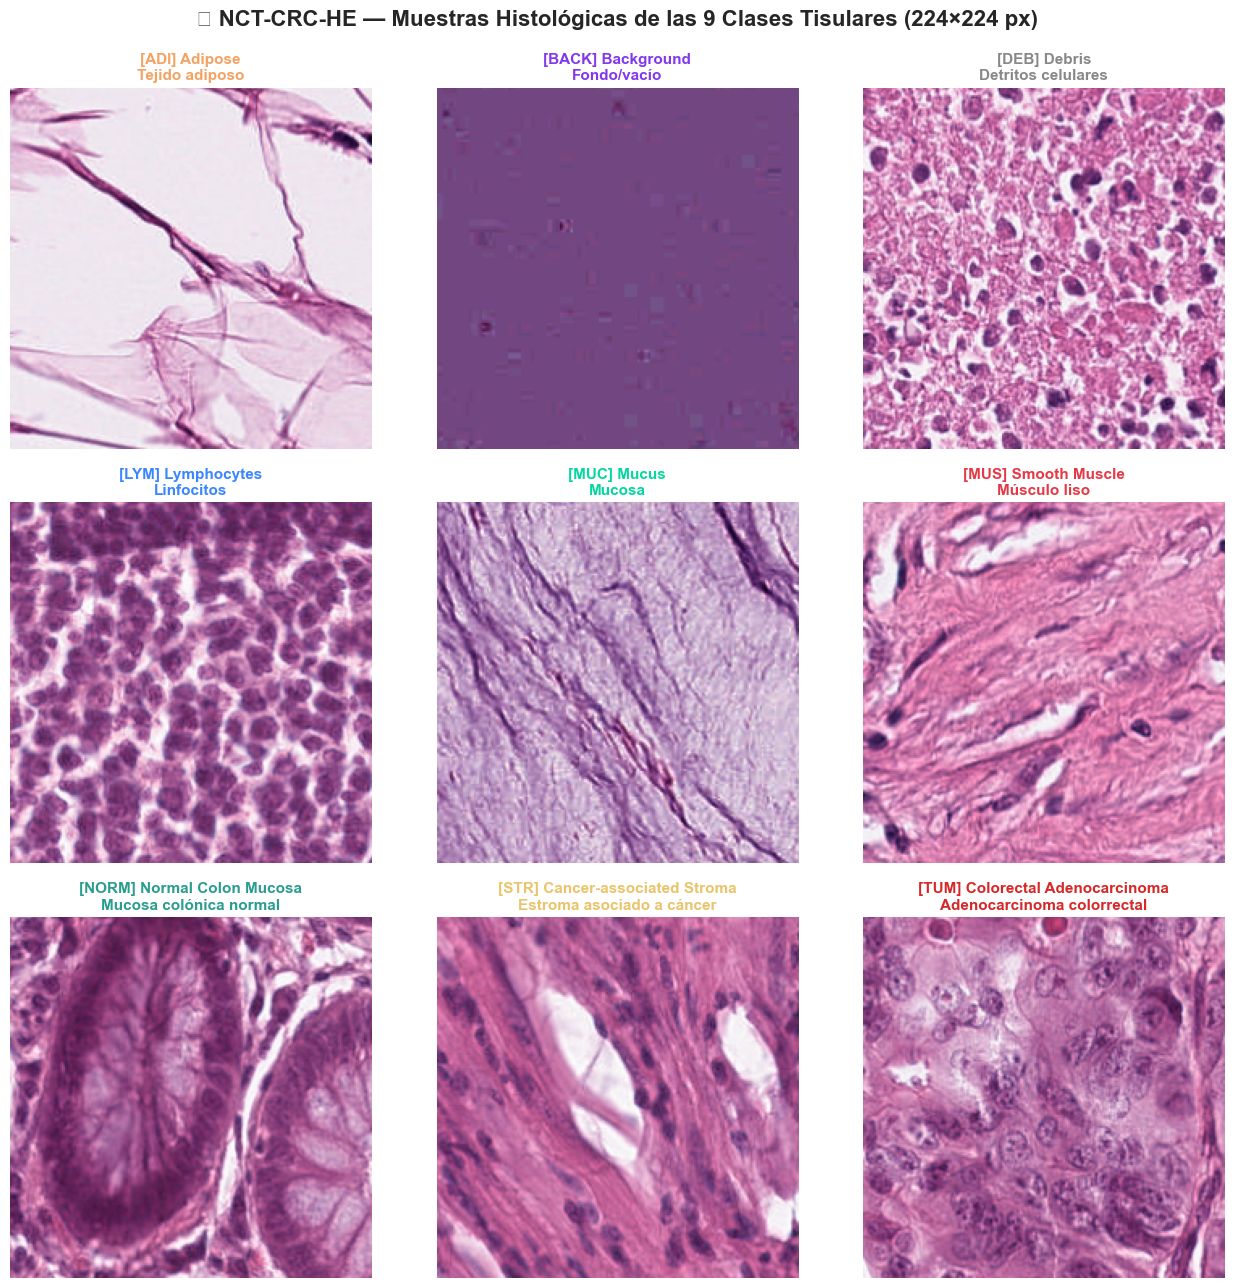

In [6]:
# ============================================================
# 6. CUADRÍCULA DE MUESTRAS HISTOLÓGICAS (9 CLASES TISULARES)
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
fig.suptitle('🔬 NCT-CRC-HE — Muestras Histológicas de las 9 Clases Tisulares (224×224 px)',
             fontsize=16, fontweight='bold', y=0.99)

for idx, (codigo, info) in enumerate(CLASES_NCT.items()):
    ax = axes[idx // 3][idx % 3]
    sub = df_val[df_val['clase_codigo'] == codigo]
    if len(sub) == 0 and len(df_train) > 0:
        sub = df_train[df_train['clase_codigo'] == codigo]
        
    if len(sub) > 0:
        sample_path = sub.sample(1, random_state=42)['path'].iloc[0]
        try:
            img = Image.open(sample_path)
            ax.imshow(img)
            ax.set_title(f"[{codigo}] {info['nombre']}\n{info['desc']}",
                         fontsize=11, fontweight='bold', color=info['color'])
            ax.axis('off')
        except Exception as e:
            ax.text(0.5, 0.5, f'Error al cargar:\n{codigo}', ha='center', va='center')
            ax.axis('off')
    else:
        ax.text(0.5, 0.5, f'Sin imagen:\n{codigo}', ha='center', va='center')
        ax.axis('off')

plt.tight_layout()
muestras_path = FIG_DIR / 'nct_muestras_por_clase.png'
fig.savefig(str(muestras_path), dpi=150, bbox_inches='tight')
print(f'✅ Cuadrícula de muestras guardada: {muestras_path}')
guardar_subplots_individuales(fig, 'nct_muestras_por_clase', FIG_DIR, dpi=150)
plt.show()


---
### 📌 ¿Qué hace esta celda?
Selecciona aleatoriamente pero de forma reproducible (`random_state=42`) un parche histológico representativo de 224×224 píxeles para cada una de las 9 clases tisulares. Construye una cuadrícula visual de 3×3 con anotaciones morfológicas y exporta la cuadrícula combinada `nct_muestras_por_clase.png` y sus 9 paneles individuales.
---


In [7]:
# ============================================================
# 7. CARACTERIZACIÓN ESTADÍSTICA RGB POR CLASE
# ============================================================
def compute_rgb_stats(df, max_samples_per_class=300):
    dataset_name = df['dataset'].iloc[0] if len(df) > 0 else 'Unknown'
    print(f'🔬 Calculando estadísticas RGB para {dataset_name} ({max_samples_per_class} parches/clase)...')
    stats_list = []
    
    for codigo, info in CLASES_NCT.items():
        sub_df = df[df['clase_codigo'] == codigo]
        if len(sub_df) == 0:
            continue
        n_sample = min(len(sub_df), max_samples_per_class)
        sampled = sub_df.sample(n=n_sample, random_state=42)
        
        r_means, g_means, b_means = [], [], []
        r_stds, g_stds, b_stds = [], [], []
        
        for path_str in sampled['path']:
            try:
                img = Image.open(path_str).convert('RGB')
                arr = np.asarray(img, dtype=np.float32)
                r_means.append(float(np.mean(arr[:, :, 0])))
                g_means.append(float(np.mean(arr[:, :, 1])))
                b_means.append(float(np.mean(arr[:, :, 2])))
                r_stds.append(float(np.std(arr[:, :, 0])))
                g_stds.append(float(np.std(arr[:, :, 1])))
                b_stds.append(float(np.std(arr[:, :, 2])))
            except Exception as e:
                pass
                
        stats_list.append({
            'dataset': dataset_name,
            'clase_codigo': codigo,
            'clase_nombre': info['nombre'],
            'n_muestreadas': len(r_means),
            'r_media': round(float(np.mean(r_means)), 2),
            'r_std': round(float(np.mean(r_stds)), 2),
            'g_media': round(float(np.mean(g_means)), 2),
            'g_std': round(float(np.mean(g_stds)), 2),
            'b_media': round(float(np.mean(b_means)), 2),
            'b_std': round(float(np.mean(b_stds)), 2),
            'brillo_global': round((float(np.mean(r_means)) + float(np.mean(g_means)) + float(np.mean(b_means))) / 3.0, 2)
        })
    return pd.DataFrame(stats_list)

dfs_rgb = []
if len(df_val) > 0:
    dfs_rgb.append(compute_rgb_stats(df_val))
if len(df_train) > 0:
    dfs_rgb.append(compute_rgb_stats(df_train))

if dfs_rgb:
    df_rgb_all = pd.concat(dfs_rgb, ignore_index=True)
    rgb_excel = TABLAS_DIR / 'nct_rgb_stats_por_clase.xlsx'
    df_rgb_all.to_excel(rgb_excel, index=False)
    print(f'✅ Tabla de estadísticas RGB guardada: {rgb_excel}')
    
    print('\n🔬 RESUMEN DE ESTADÍSTICAS RGB POR CLASE (VALIDACIÓN):')
    print(df_rgb_all[df_rgb_all['dataset'] == 'CRC-VAL-HE-7K'][['clase_codigo', 'clase_nombre', 'r_media', 'g_media', 'b_media', 'brillo_global']].to_string(index=False))


🔬 Calculando estadísticas RGB para CRC-VAL-HE-7K (300 parches/clase)...


🔬 Calculando estadísticas RGB para NCT-CRC-HE-100K (300 parches/clase)...


✅ Tabla de estadísticas RGB guardada: ..\tablas\nct_rgb_stats_por_clase.xlsx

🔬 RESUMEN DE ESTADÍSTICAS RGB POR CLASE (VALIDACIÓN):
clase_codigo              clase_nombre  r_media  g_media  b_media  brillo_global
         ADI                   Adipose   223.28   202.35   221.32         215.65
        BACK                Background   122.23    78.14   133.53         111.30
         DEB                    Debris   186.62    98.62   209.03         164.76
         LYM               Lymphocytes   181.52   132.07   173.97         162.52
         MUC                     Mucus   189.79   150.57   190.67         177.01
         MUS             Smooth Muscle   192.16   118.65   166.30         159.04
        NORM       Normal Colon Mucosa   189.73   135.88   177.94         167.85
         STR  Cancer-associated Stroma   189.25   124.52   177.52         163.76
         TUM Colorectal Adenocarcinoma   175.56   115.97   163.23         151.59


---
### 📌 ¿Qué hace esta celda?
Realiza una caracterización espectral computando las medias y desviaciones estándar para cada canal cromático (Rojo, Verde, Azul) y el brillo promedio global ($I = (R+G+B)/3$) sobre un muestreo estratificado representativo por clase. Esta caracterización es crítica para cuantificar la intensidad de tinción H&E y detectar necesidad de normalización Macenko o Vahadane.
---


In [8]:
# ============================================================
# 8. ESPECIFICACIONES TÉCNICAS Y REPORTE CLÍNICO / MIL
# ============================================================
df_specs = pd.DataFrame([
    {'Parámetro': 'Dataset de Entrenamiento', 'Valor': 'NCT-CRC-HE-100K (100,000 parches)'},
    {'Parámetro': 'Dataset de Validación', 'Valor': 'CRC-VAL-HE-7K (7,180 parches)'},
    {'Parámetro': 'Cohorte de Validación', 'Valor': '50 pacientes independientes con CRC'},
    {'Parámetro': 'Número de Clases Tisulares', 'Valor': '9 categorías histológicas'},
    {'Parámetro': 'Resolución Espacial', 'Valor': '224 × 224 píxeles (RGB no comprimido)'},
    {'Parámetro': 'Magnificación y Resolución Óptica', 'Valor': '20x (~0.5 µm/píxel)'},
    {'Parámetro': 'Tinción Histológica', 'Valor': 'Hematoxilina y Eosina (H&E)'},
    {'Parámetro': 'Normalización de Tinción', 'Valor': 'Macenko stain normalization'},
    {'Parámetro': 'Almacenamiento en Disco (Extraído)', 'Valor': '~11.15 GB (Train) + ~763 MB (Val)'},
    {'Parámetro': 'Utilidad en Modelos MIL (CLAM, ABMIL)', 'Valor': 'Preentrenamiento autosupervisado (SSL) y clasificación de microentorno'},
])

specs_excel = TABLAS_DIR / 'nct_crc_especificaciones.xlsx'
df_specs.to_excel(specs_excel, index=False)
print(f'✅ Especificaciones técnicas consolidadas: {specs_excel}')
print(df_specs.to_string(index=False))


✅ Especificaciones técnicas consolidadas: ..\tablas\nct_crc_especificaciones.xlsx
                            Parámetro                                                                  Valor
             Dataset de Entrenamiento                                      NCT-CRC-HE-100K (100,000 parches)
                Dataset de Validación                                          CRC-VAL-HE-7K (7,180 parches)
                Cohorte de Validación                                    50 pacientes independientes con CRC
           Número de Clases Tisulares                                              9 categorías histológicas
                  Resolución Espacial                                  224 × 224 píxeles (RGB no comprimido)
    Magnificación y Resolución Óptica                                                    20x (~0.5 µm/píxel)
                  Tinción Histológica                                            Hematoxilina y Eosina (H&E)
             Normalización de Tinción         

---
### 📌 Conclusiones y Relevancia para la Tesis de Magíster
1. **Representatividad Tisular**: NCT-CRC-HE proporciona una taxonomía balanceada que cubre tanto el compartimento neoplásico (`TUM`) como el microentorno estromal (`STR`), inmune (`LYM`), muscular (`MUS`) y de fondo (`BACK`, `DEB`), permitiendo entrenar clasificadores de parches altamente robustos.
2. **Validación Externa Rigurosa**: La existencia del conjunto `CRC-VAL-HE-7K` proveniente de 50 pacientes independientes asegura que los modelos entrenados en el conjunto de 100K no sufran de sobreajuste por paciente (*patient-level data leakage*).
3. **Compatibilidad con Arquitecturas MIL**: Los parches de 224×224 px constituyen la unidad base estándar para modelos de Aprendizaje Débilmente Supervisado (Multiple Instance Learning) como CLAM, ABMIL y TransMIL.
